# Explicabilidade do Recomendador — SHAP e decomposição do híbrido

Um sistema de recomendação sênior precisa ser **explicável** em dois níveis:

1. **Nível de sistema** — de onde vem cada ponto do score? O híbrido
   `z(log1p(pop)) + alpha * z(NeuMF)` permite separar a parte **não personalizada**
   (popularidade) da parte **personalizada** (a rede aplicada ao cliente).
2. **Nível de modelo** — como cada entrada (cliente, produto, categoria,
   subcategoria) contribui para o score neural? Usamos **SHAP** (*KernelExplainer*)
   sobre a função de score.

## 1. Configuração do ambiente

In [1]:
import sys
from pathlib import Path

# Localiza a raiz do projeto (onde está o pyproject.toml) para importar `src.*`.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import joblib
import keras
import numpy as np
import pandas as pd
import tensorflow as tf

from src.config.model_utils import (
    build_item_catalog,
    combine_scores,
    score_catalog,
    train_validation_test_split,
)
from src.config.paths import DADOS_TRATADOS, MODELS_DIR, REPORTS_DIR

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Projeto:", ROOT)
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

import matplotlib.pyplot as plt
import shap

%matplotlib inline
FIG_DIR = REPORTS_DIR / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)
FEATURES = ["Cliente", "Produto", "Categoria", "Subcategoria"]
print("SHAP:", shap.__version__)

Projeto: C:\Users\flavi\Documents\GitHub\Sistema_Recomendacao_Arquitetura-MLOps
TensorFlow: 2.19.0 | Keras: 3.9.0


SHAP: 0.49.1


## 2. Carregamento do modelo, dados e catálogo

In [2]:
dados = pd.read_parquet(DADOS_TRATADOS)
encoders = {
    nome: joblib.load(MODELS_DIR / f"{nome}_encoder_otimizado.pkl")
    for nome in ["customer", "product", "category", "subcategory"]
}
modelo = tf.keras.models.load_model(MODELS_DIR / "best_model_recomendacao_otimizado.keras")
config_hibrido = joblib.load(MODELS_DIR / "hybrid_config_otimizado.pkl")

alpha = float(config_hibrido["alpha"])
prior_popularidade = config_hibrido["popularity"]
num_produtos = len(encoders["product"].classes_)
catalogo = build_item_catalog(
    dados, encoders["product"], encoders["category"], encoders["subcategory"]
)

train_pairs, val_pairs, test_pairs = train_validation_test_split(
    dados, encoders["customer"], encoders["product"]
)

print("Interações:", dados.shape)
print(f"Clientes: {len(encoders['customer'].classes_)} | Produtos: {num_produtos} "
      f"| Categorias: {len(encoders['category'].classes_)}")
print(f"Pares -> treino: {len(train_pairs)} | validação: {len(val_pairs)} | teste: {len(test_pairs)}")
print(f"alpha do híbrido (produção): {alpha}")

Interações: (9800, 18)
Clientes: 793 | Produtos: 1861 | Categorias: 3
Pares -> treino: 8171 | validação: 776 | teste: 776
alpha do híbrido (produção): 0.0


## 3. Nível de sistema — decomposição do score híbrido

Para um cliente, decompomos o score final em:

- **Prior (popularidade)** — sinal global, igual para todos, mas ponderado pelo log;
- **Personalizado** — `alpha * z(NeuMF)`, o ajuste que a rede faz para *este* cliente.

Quando `alpha = 0` (caso desta base), a coluna personalizada é nula por construção: o
ranking é puramente popular. A análise SHAP a seguir mostra **por que** o sinal
personalizado é desprezível neste caso.

In [3]:
CLIENTE = "Irene Maddox"
cid = int(encoders["customer"].transform([CLIENTE])[0])

scores_neural = score_catalog(modelo, [cid], catalogo)[0]
componente_pop = combine_scores(scores_neural[None, :], prior_popularidade, alpha=0.0)[0]
score_hibrido = combine_scores(scores_neural[None, :], prior_popularidade, alpha=alpha)[0]
componente_neural = score_hibrido - componente_pop

# Exclui itens já comprados para listar apenas candidatos.
comprados = set(encoders["product"].transform(
    dados[dados["Customer Name"] == CLIENTE]["Product ID"]
))
ranking = [i for i in np.argsort(-score_hibrido) if i not in comprados][:10]

decomposicao = pd.DataFrame({
    "Product ID": encoders["product"].inverse_transform(ranking),
    "prior (z)": componente_pop[ranking],
    "personalizado (alpha*z_NeuMF)": componente_neural[ranking],
    "score híbrido": score_hibrido[ranking],
})
decomposicao.round(4)

,Product ID,prior (z),personalizado (alpha*z_NeuMF),score híbrido
0,TEC-AC-10003832,2.6680,0.0,2.6680
1,OFF-PA-10001970,2.6680,0.0,2.6680
2,OFF-BI-10000977,2.2532,0.0,2.2532
3,TEC-AC-10003628,2.2532,0.0,2.2532
4,OFF-BI-10004140,2.2532,0.0,2.2532
5,FUR-CH-10001146,2.0949,0.0,2.0949
6,TEC-AC-10003038,2.0949,0.0,2.0949
7,FUR-FU-10004864,2.0949,0.0,2.0949
8,TEC-AC-10002049,2.0949,0.0,2.0949
9,FUR-CH-10002647,2.0949,0.0,2.0949


## 4. Nível de modelo — SHAP sobre o score neural

O score neural é uma função de quatro entradas inteiras (cliente, produto, categoria,
subcategoria). Usamos `shap.KernelExplainer` com um *background* de interações
observadas. `nsamples` controla o custo (aproximação de prazos); mantemos um valor
baixo por ser uma análise introdutória.

In [4]:
amostra = dados.sample(120, random_state=42)

X_all = np.column_stack([
    encoders["customer"].transform(amostra["Customer Name"]),
    encoders["product"].transform(amostra["Product ID"]),
    encoders["category"].transform(amostra["Category"]),
    encoders["subcategory"].transform(amostra["Sub-Category"]),
]).astype("int64")

background = X_all[:40]
X_explain = X_all[40:80]


def funcao_score(X):
    X = np.asarray(X)
    return modelo.predict(
        [
            X[:, 0].reshape(-1, 1),
            X[:, 1].reshape(-1, 1),
            X[:, 2].reshape(-1, 1),
            X[:, 3].reshape(-1, 1),
        ],
        verbose=0,
    ).ravel()


explainer = shap.KernelExplainer(funcao_score, background)
shap_values = explainer.shap_values(X_explain, nsamples=100)
shap_values = np.asarray(shap_values)
print("shap_values:", shap_values.shape)

importancia = pd.Series(
    np.abs(shap_values).mean(axis=0), index=FEATURES
).sort_values(ascending=False)
importancia.round(5)

  0%|          | 0/40 [00:00<?, ?it/s]

shap_values: (40, 4)


Subcategoria    0.00729
Categoria       0.00094
Cliente         0.00000
Produto         0.00000
dtype: float64

## 5. Visualizações SHAP

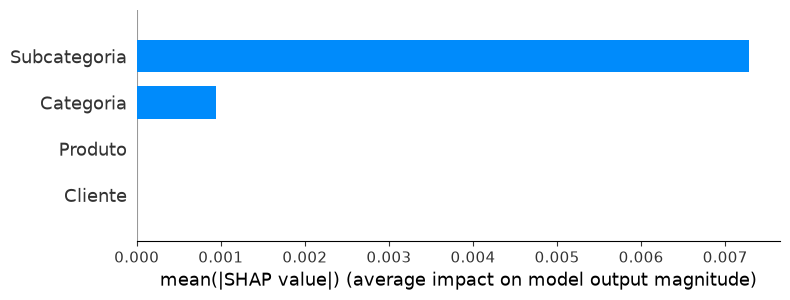

In [5]:
shap.summary_plot(shap_values, X_explain, feature_names=FEATURES, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_bar_plot.png", dpi=150, bbox_inches="tight")
plt.show()

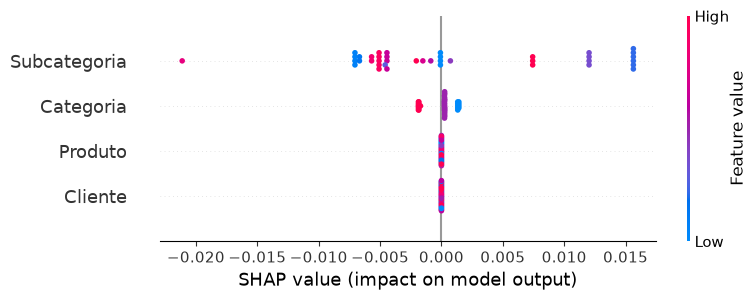

In [6]:
shap.summary_plot(shap_values, X_explain, feature_names=FEATURES, show=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "shap_summary_plot.png", dpi=150, bbox_inches="tight")
plt.show()

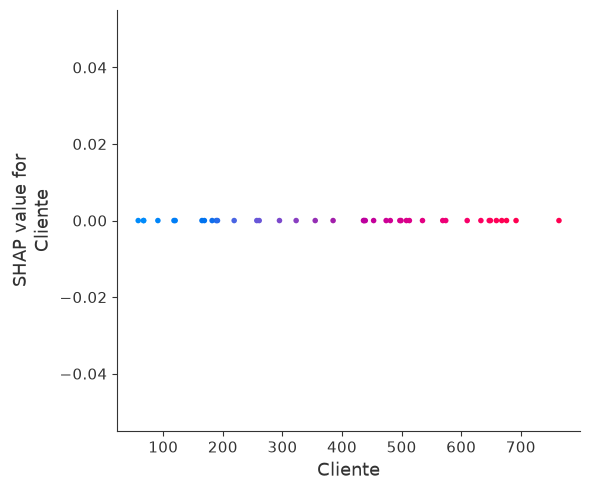

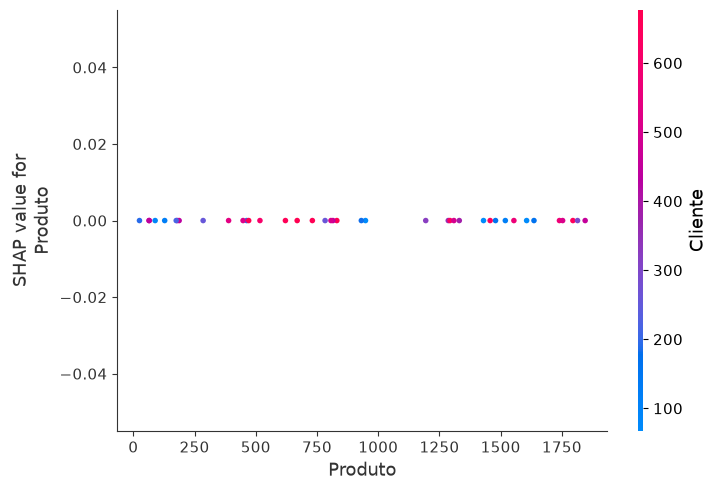

In [7]:
for idx, nome in enumerate(FEATURES[:2]):
    shap.dependence_plot(idx, shap_values, X_explain, feature_names=FEATURES, show=False)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"shap_dependence_{nome.lower()}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 6. Explicação de uma recomendação individual

Para a primeira instância explicada, mostramos como cada entrada empurra o score
acima ou abaixo da esperança do modelo (`base_values`).

In [8]:
i = 0
contrib = pd.Series(shap_values[i], index=FEATURES).sort_values(key=np.abs, ascending=False)
print("Esperança do modelo (base value):", round(float(np.ravel(explainer.expected_value)[0]), 5))
print("Score previsto:", round(float(funcao_score(X_explain[i:i+1])[0]), 5))
print()
print("Contribuição por entrada:")
contrib.round(5)

Esperança do modelo (base value): 0.10545
Score previsto: 0.10349

Contribuição por entrada:


Categoria      -0.00188
Subcategoria   -0.00008
Cliente         0.00000
Produto         0.00000
dtype: float64

## 7. Verificação independente do SHAP

SHAP é uma *atribuição*: para não confiar apenas nela, medimos diretamente o efeito
de cada entrada **permutando** a coluna (se o score não muda ao permutar, a entrada
não influencia a previsão) e inspecionamos a magnitude dos embeddings aprendidos.

In [9]:
rng = np.random.default_rng(0)


def efeito_da_entrada(coluna):
    Xp = X_explain.copy()
    Xp[:, coluna] = X_explain[rng.permutation(len(X_explain)), coluna]
    return float(np.abs(funcao_score(Xp) - funcao_score(X_explain)).mean())


efeitos = pd.Series(
    {nome: efeito_da_entrada(i) for i, nome in enumerate(FEATURES)}
).round(6)
print("|Δ score| médio ao permutar cada entrada (0 = o modelo ignora a entrada):")
print(efeitos.to_string())
print()
print("Magnitude dos embeddings aprendidos (|W|max):")
for nome in ["customer_embedding", "product_embedding", "category_embedding", "subcategory_embedding"]:
    w = modelo.get_layer(nome).get_weights()[0]
    print(f"  {nome:22s} |W|max = {np.abs(w).max():.6f}  std = {w.std():.6f}")

|Δ score| médio ao permutar cada entrada (0 = o modelo ignora a entrada):
Cliente         0.000000
Produto         0.000000
Categoria       0.001145
Subcategoria    0.008615

Magnitude dos embeddings aprendidos (|W|max):
  customer_embedding     |W|max = 0.000000  std = 0.000000
  product_embedding      |W|max = 0.000000  std = 0.000000
  category_embedding     |W|max = 0.115556  std = 0.048167
  subcategory_embedding  |W|max = 0.141193  std = 0.038139


## 8. Conclusão

- **Nível de sistema:** o híbrido permite ler o score como *popularidade + ajuste
  personalizado*, o que é diretamente acionável pelo negócio.
- **Nível de modelo:** nesta base o SHAP concentra a contribuição em
  **categoria/subcategoria**, enquanto **cliente** e **produto** têm efeito ≈ 0. A
  verificação independente confirma: permutar cliente ou produto **não altera o
  score**, e os embeddings desses dois campos estão **numericamente colapsados**
  (`|W|max` ~ 1e-6).
- **Por quê:** com cada cliente consumindo ~12 itens num catálogo de ~1.900, o sinal
  personalizado é fraco; a regularização L2 sobre os embeddings de alta cardinalidade
  os leva a zero e o modelo **reverte para um prior de categoria**. Essa é a evidência
  *ao nível do modelo* do que a avaliação já indicava — e é exatamente por isso que o
  híbrido escolhe `alpha = 0` e a produção usa o prior de popularidade.

Limitações e próximos passos: `KernelExplainer` é uma aproximação (custo alto). Para
produzir **personalização real** seriam necessárias features contextuais (sazonalidade,
cesta/conjunto de compra); enquanto esse sinal não existir nos dados, a resposta honesta
do sistema é o prior de popularidade. Para produção, considerar `GradientExplainer`/DeepSHAP.